# Análise Exploratória de Dados

Esta análise busca caracterizar o conjunto de dados de forma sistemática,
identificando sua estrutura, distribuições, valores ausentes, inconsistências
e possíveis pontos de atenção para pré-processamento e avaliação de modelos de
IA generativa.

## Carregando o conjunto de dados

In [1]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast

ID_DATASET = "Weni/WeniEval-Benchmark-2.0.0"

dataset = load_dataset(ID_DATASET)
df = dataset["train"].to_pandas()

/home/vitoria/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ROXO = "#6F42C1"
ROXO_ESCURO = "#4B2E83"
ROXO_CLARO = "#D9C7F2"
FUNDO = "#FCFAFF"

def estilizar_grafico(ax, eixo_grade="y"):
    # para manter o mesmo padrão visual em todos os gráficos
    ax.set_facecolor(FUNDO)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=eixo_grade, alpha=0.18, linestyle="--")
    ax.set_axisbelow(True)
    plt.tight_layout()

### Splits disponíveis

Antes de criar qualquer divisão própria de treino e teste, é importante
verificar se o conjunto já fornece 'train', 'validation' ou 'test' oficiais.

In [3]:
dataset.keys()

dict_keys(['train'])

A documentação consultada indica apenas o split 'train', mas a célula acima confirma isso diretamente no objeto carregado. Se apenas 'train' estiver disponível, qualquer divisão adicional deverá ser construída pelo próprio experimento e precisa preservar a estrutura de grupos relacionados do conjunto.

## Visão geral do conjunto de dados

In [4]:
df.head()

,content,context_metadata,question,type_question,type_feature,name,occupation,instructions,chatbot_goal,adjective,data_category,id,chunks_big,classes,chosen_class_id,language,data_category_QA,content_base_uuids
0,PERGUNTAS FREQUENTES\n\n ...,"{'kind': 'customsearch#result', 'title': 'Perg...",Roupas troca prazo?,simple,Lexical entropy low,Bella,Atendente de E-commerce,"[Responda sempre educadamente e com empatia, U...","Oferecer suporte sobre produtos, frete, person...",Criativo,text_generation,1,[{'content': 'PERGUNTAS FREQUENTES ...,"[{'class': 'iluminação', 'context': 'quando há...",P1,0,positivo,5db3c3c5-c9fc-44ec-991d-dc32f9bd37d5
1,PERGUNTAS FREQUENTES\n\n ...,"{'kind': 'customsearch#result', 'title': 'Perg...",Qual email usar?,simple,Lexical entropy low,Bazarino,Profissão: Atendente de E-commerce,[Finalize a resposta com um emoji de animal e ...,"Facilitar trocas, prazos, contatos, dúvidas, e...",Relaxado,text_generation,2,"[{'content': 'Se, após a primeira troca, o usu...","[{'class': 'trocas_após_primeira', 'context': ...",P1,0,positivo,e7d321f2-e0f7-4ee7-aa0d-cb7947b837bf
2,Perguntas Frequentes\n\nQuais as formas de pag...,"{'kind': 'customsearch#result', 'title': 'Loja...",Quais serviços usados para realizar envios?,simple,Lexical entropy low,Felicio,Atendente de E-commerce,[Responda de forma objetiva e clara sempre que...,O Chatbot é para fornecer informações sobre pa...,Generoso,text_generation,3,[{'content': 'Perguntas Frequentes Quais as f...,"[{'class': 'pagamento', 'context': 'Referente ...",P1,0,positivo,363de0bd-a2fe-4045-92d3-6af39fc97f17
3,Perguntas Frequentes\n\nQuais as formas de pag...,"{'kind': 'customsearch#result', 'title': 'Loja...",Como ser notificado de disponibilidade novamen...,simple,Lexical entropy low,Frederico.,Atendente de Suporte ao Cliente em E-commerce,[Responda sempre mencionando a Shoes Julis de ...,Proporcionar suporte completo aos clientes Sho...,Inovador,text_generation,4,[{'content': 'Para ser notificado quando o pro...,"[{'class': 'notificacao_estoque', 'context': '...",P1,0,positivo,1eb07a54-7803-4816-b146-2c8a5e82e497
4,Perguntas Frequentes\n\n1. QUAIS SÃO AS FORMAS...,"{'kind': 'customsearch#result', 'title': 'Perg...",Quais tipos cartões aceitam para realizar paga...,simple,Lexical entropy low,Maximus,Atendente de Loja Virtual,"[Em todas as respostas, enfatize a transparênc...",Auxiliar com informações sobre formas de pagam...,Sistemático,text_generation,5,[{'content': 'Perguntas Frequentes 1. QUAIS S...,"[{'class': 'política_de_privacidade', 'context...",P1,0,positivo,61f16329-e698-4106-88c7-fd23dac0a70d


In [5]:
df.shape

(3887, 18)

In [6]:
df.columns.tolist()

['content',
 'context_metadata',
 'question',
 'type_question',
 'type_feature',
 'name',
 'occupation',
 'instructions',
 'chatbot_goal',
 'adjective',
 'data_category',
 'id',
 'chunks_big',
 'classes',
 'chosen_class_id',
 'language',
 'data_category_QA',
 'content_base_uuids']

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3887 entries, 0 to 3886
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   content             3887 non-null   object
 1   context_metadata    3887 non-null   object
 2   question            3887 non-null   object
 3   type_question       3887 non-null   object
 4   type_feature        3887 non-null   object
 5   name                3887 non-null   object
 6   occupation          3887 non-null   object
 7   instructions        3887 non-null   object
 8   chatbot_goal        3887 non-null   object
 9   adjective           3887 non-null   object
 10  data_category       3887 non-null   object
 11  id                  3887 non-null   object
 12  chunks_big          3887 non-null   object
 13  classes             3887 non-null   object
 14  chosen_class_id     3887 non-null   object
 15  language            3887 non-null   int64 
 16  data_category_QA    3887

O conjunto possui 3.887 registros e 18 colunas. Há variáveis textuais, categóricas, identificadores e estruturas aninhadas, como listas de instruções, chunks e classes.

Para evitar o custo de 'df.describe(include="all")' sobre listas e dicionários, a visão geral abaixo calcula cardinalidade apenas nas colunas simples.

In [8]:
# colunas que possuem estruturas aninhadas e, por isso, não terão contagem de valores únicos
colunas_aninhadas = {"instructions", "chunks_big", "classes"}

# cria um resumo inicial com o tipo de cada coluna e a quantidade de valores ausentes
resumo_geral = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes_nan": df.isna().sum()
})

# conta os valores únicos apenas nas colunas simples
resumo_geral["valores_unicos"] = [
    "-" if coluna in colunas_aninhadas else df[coluna].nunique(dropna=False)
    for coluna in df.columns
]

resumo_geral

,tipo,ausentes_nan,valores_unicos
content,object,0,548
context_metadata,object,0,356
question,object,0,3849
type_question,object,0,16
type_feature,object,0,30
name,object,0,834
occupation,object,0,1724
instructions,object,0,-
chatbot_goal,object,0,3881
adjective,object,0,24


### Qualidade geral dos dados

'df.isna()' não encontra valores ausentes no nível principal das 18 colunas.
Entretanto, algumas variáveis categóricas utilizam strings como 'nan', 'None'
ou uma string vazia para representar ausência. Esses casos precisam ser
tratados separadamente.

In [9]:
# resume a quantidade e o percentual de valores ausentes em cada coluna
qualidade_dados = pd.DataFrame({
    "valores_ausentes_nan": df.isna().sum(),
    "percentual_nan": (df.isna().mean() * 100).round(2)
})

qualidade_dados

,valores_ausentes_nan,percentual_nan
content,0,0.0
context_metadata,0,0.0
question,0,0.0
type_question,0,0.0
type_feature,0,0.0
name,0,0.0
occupation,0,0.0
instructions,0,0.0
chatbot_goal,0,0.0
adjective,0,0.0


In [10]:
# valores que podem representar ausência de informação em colunas de texto
marcadores_ausencia = {"", "nan", "none", "null"}

def contar_ausencias_textuais(serie):
    # ignora colunas aninhadas, que não são adequadas para essa verificação
    if serie.name in colunas_aninhadas:
        return 0

    # padroniza os valores para facilitar a identificação dos marcadores de ausência
    valores = serie.astype(str).str.strip().str.lower()

    # conta quantos valores correspondem aos marcadores definidos
    return valores.isin(marcadores_ausencia).sum()


# aplica a verificação em todas as colunas e ordena pelas maiores contagens
ausencias_textuais = pd.Series({
    coluna: contar_ausencias_textuais(df[coluna])
    for coluna in df.columns
}).sort_values(ascending=False)

# exibe apenas as colunas em que foram encontrados marcadores de ausência
ausencias_textuais[ausencias_textuais > 0]

type_question    2790
type_feature      597
dtype: int64

Foram encontrados 2.790 valores ausentes, ou equivalentes a ausentes, em type_question e 597 em type_feature, mesmo que esses casos não sejam identificados pelo isna(). 

Esse resultado mostra que olhar apenas para isna() pode dar a impressão de que o conjunto está totalmente preenchido, quando na verdade existem valores ausentes registrados como texto.


In [11]:
# as estruturas aninhadas são convertidas para texto apenas para comparar as linhas
linhas_duplicadas = df.astype(str).duplicated().sum()

print("Linhas totalmente duplicadas:", linhas_duplicadas)

Linhas totalmente duplicadas: 0


Não foram encontradas linhas completamente duplicadas no conjunto. Ainda assim, isso não significa que todos os registros sejam totalmente diferentes, já que conteúdos, perguntas ou identificadores podem aparecer mais de uma vez em linhas distintas.

## Caracterização das variáveis

Cada tipo de coluna será analisado de uma forma diferente. Nos textos, serão observados pontos como valores ausentes, repetição e tamanho. Nas colunas categóricas, serão verificadas as frequências e possíveis inconsistências. Já nas colunas com listas ou dicionários, a análise será voltada para a estrutura e a quantidade de elementos.

### content

A coluna 'content' contém o texto de referência associado a cada exemplo.
Ela pode funcionar como contexto para a pergunta presente em 'question'.

In [12]:
df["content"].head()

0    PERGUNTAS FREQUENTES\n\n                      ...
1    PERGUNTAS FREQUENTES\n\n                      ...
2    Perguntas Frequentes\n\nQuais as formas de pag...
3    Perguntas Frequentes\n\nQuais as formas de pag...
4    Perguntas Frequentes\n\n1. QUAIS SÃO AS FORMAS...
Name: content, dtype: object

In [13]:
# cria um resumo da coluna content
content_summary = pd.DataFrame({
    "Quantidade de registros": [len(df)],
    "Valores ausentes": [df["content"].isna().sum()],
    "Strings vazias": [df["content"].fillna("").str.strip().eq("").sum()],
    "Valores únicos": [df["content"].nunique()],
    "Registros que repetem um valor anterior": [df["content"].duplicated().sum()]
})

content_summary

,Quantidade de registros,Valores ausentes,Strings vazias,Valores únicos,Registros que repetem um valor anterior
0,3887,0,0,548,3339


A coluna content possui 3.887 registros e não apresenta valores ausentes ou strings vazias. Apesar disso, existem apenas 548 conteúdos diferentes. Os outros 3.339 registros repetem algum valor de content que já apareceu anteriormente.

Isso mostra que há bastante reutilização de conteúdo na base. Essa repetição não significa que as linhas sejam completamente duplicadas, já que outros campos, como pergunta, idioma ou categoria, podem ser diferentes.


In [14]:
content_counts = df["content"].value_counts()
content_frequency = content_counts.value_counts().sort_index()

content_frequency

count
3     223
5       1
6     257
9       7
12     10
15      1
18      5
21      2
22      1
24      4
27      4
30      9
32      1
33      9
36     12
39      1
45      1
Name: count, dtype: int64

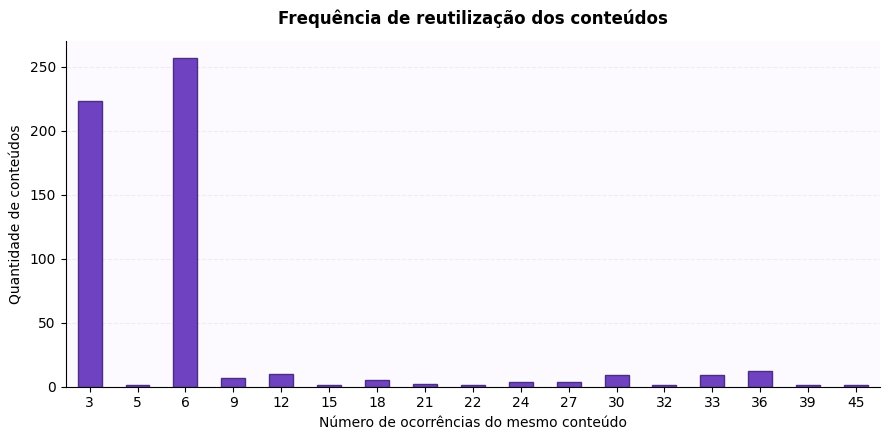

In [15]:
ax = content_frequency.plot(
    kind="bar",
    figsize=(9, 4.5),
    color=ROXO,
    edgecolor=ROXO_ESCURO
)

ax.set_xlabel("Número de ocorrências do mesmo conteúdo")
ax.set_ylabel("Quantidade de conteúdos")
ax.set_title("Frequência de reutilização dos conteúdos", pad=12, weight="bold")
ax.tick_params(axis="x", rotation=0)

estilizar_grafico(ax)
plt.show()

Os conteúdos são reutilizados diversas vezes ao longo da base. A maior parte aparece 3 ou 6 vezes, mas alguns contextos chegam a ocorrer até 45 vezes. Isso reforça a necessidade de considerar a origem do contexto ao criar divisões de treino e teste.

In [16]:
# identifica todos os registros que possuem a mesma combinação de content e question
# keep=False marca tanto a primeira ocorrência quanto as repetições
duplicatas_content_question = df.duplicated(
    subset=["content", "question"],
    keep=False
)

# quantidade total de registros envolvidos em combinações repetidas
print(
    "Registros envolvidos em pares content + question repetidos:",
    duplicatas_content_question.sum()
)

# quantidade de repetições desconsiderando a primeira ocorrência de cada combinação
print(
    "Repetições além da primeira ocorrência:",
    df.duplicated(subset=["content", "question"]).sum()
)

# exibe alguns exemplos dessas combinações repetidas
df.loc[
    duplicatas_content_question,
    ["id", "content", "question", "language"]
].head(20)

Registros envolvidos em pares content + question repetidos: 8
Repetições além da primeira ocorrência: 4


,id,content,question,language
791,1098,Perguntas frequentes\n\nGeral\n\nO que é o Mas...,Quem fundou LoungeKey?,0
1129,709,Perguntas frequentes\n\nGeral\n\nO que é o Mas...,Quem fundou LoungeKey?,0
1383,91,Onde está meu produto? Rastrear pedido 0 Carri...,"If you have received the code, how long to con...",1
1384,92,Onde está meu produto? Rastrear pedido 0 Carri...,"If you have received the code, how long to con...",1
2425,709,Perguntas frequentes\n\nGeral\n\nO que é o Mas...,How many offers can I redeem daily?,1
2426,710,Perguntas frequentes\n\nGeral\n\nO que é o Mas...,How many offers can I redeem daily?,1
3382,1098,Perguntas frequentes\n\nGeral\n\nO que é o Mas...,¿Quién fundó loungekey?,2
3720,709,Perguntas frequentes\n\nGeral\n\nO que é o Mas...,¿Quién fundó loungekey?,2


Foram encontradas 4 repetições além da primeira ocorrência da combinação
'content' + 'question'. Como não existem linhas inteiras duplicadas, esses casos
devem ser inspecionados em conjunto com idioma, identificadores e demais
metadados antes de qualquer remoção.

In [17]:
df["content_chars"] = df["content"].str.len()

df["content_chars"].describe()

count     3887.000000
mean      6195.491639
std       5521.551629
min          6.000000
25%       2002.000000
50%       3656.000000
75%       9189.000000
max      29021.000000
Name: content_chars, dtype: float64

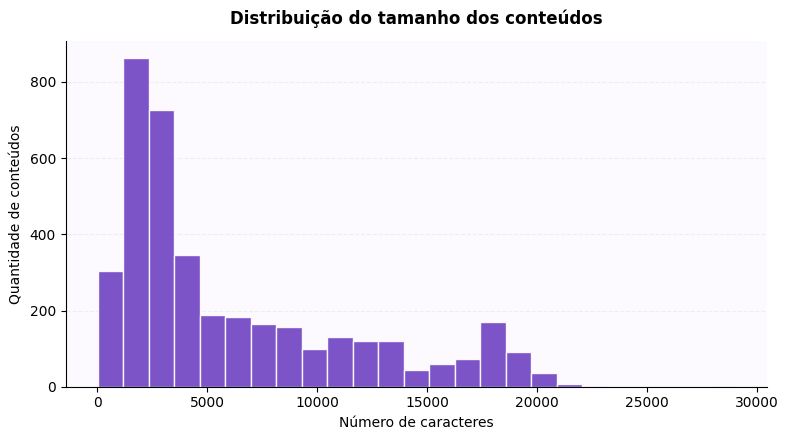

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(
    df["content_chars"],
    bins=25,
    color=ROXO,
    edgecolor="white",
    alpha=0.9
)

ax.set_xlabel("Número de caracteres")
ax.set_ylabel("Quantidade de conteúdos")
ax.set_title("Distribuição do tamanho dos conteúdos", pad=12, weight="bold")

estilizar_grafico(ax)
plt.show()

Os textos de content variam bastante de tamanho. A mediana é de 3.656 caracteres, mas a média sobe para cerca de 6.195, o que indica a presença de conteúdos bem mais longos puxando essa média para cima.

Essa variação mostra que os documentos da base não possuem um tamanho uniforme.

### context_metadata

A coluna context_metadata guarda informações sobre a origem do conteúdo, como título e endereço da página.


In [19]:
df["context_metadata"].head()


0    {'kind': 'customsearch#result', 'title': 'Perg...
1    {'kind': 'customsearch#result', 'title': 'Perg...
2    {'kind': 'customsearch#result', 'title': 'Loja...
3    {'kind': 'customsearch#result', 'title': 'Loja...
4    {'kind': 'customsearch#result', 'title': 'Perg...
Name: context_metadata, dtype: object

In [20]:
def converter_metadata(valor):
    if isinstance(valor, dict):
        return valor

    try:
        return ast.literal_eval(valor)
    except (ValueError, SyntaxError):
        return {}

metadata = df["context_metadata"].apply(converter_metadata)

metadata_keys = sorted({
    chave
    for item in metadata
    for chave in item.keys()
})

metadata_keys


['displayLink',
 'formattedUrl',
 'htmlFormattedUrl',
 'htmlSnippet',
 'htmlTitle',
 'kind',
 'link',
 'pagemap',
 'snippet',
 'title']

In [21]:
# verifica quantos domínios diferentes aparecem nos metadados
source_link = metadata.apply(lambda x: x.get("displayLink"))

print("Domínios distintos:", source_link.nunique())
print("Registros sem domínio:", source_link.isna().sum())

source_link.value_counts().head(10)


Domínios distintos: 263
Registros sem domínio: 597


context_metadata
www.action.com          210
linhandante.com          81
casadamusica.com         72
www.flytap.com           66
www.padi.com             57
www.edgenyc.com          48
www.shopify.com          45
www.br.macrobaby.com     45
www.fortestore.com       44
www.bahamas.com          42
Name: count, dtype: int64

Foram encontrados 263 domínios diferentes e 597 registros sem displayLink. Isso mostra que a origem está disponível para boa parte dos conteúdos, mas não para todos.


### question

A coluna question contém a pergunta associada a cada registro.


In [22]:
df["question"].head()


0                                  Roupas troca prazo?
1                                     Qual email usar?
2          Quais serviços usados para realizar envios?
3    Como ser notificado de disponibilidade novamen...
4    Quais tipos cartões aceitam para realizar paga...
Name: question, dtype: object

In [23]:
question_summary = pd.DataFrame({
    "Quantidade de registros": [len(df)],
    "Valores ausentes": [df["question"].isna().sum()],
    "Strings vazias": [df["question"].fillna("").str.strip().eq("").sum()],
    "Valores únicos": [df["question"].nunique()],
    "Repetições além da primeira": [df["question"].duplicated().sum()]
})

question_summary


,Quantidade de registros,Valores ausentes,Strings vazias,Valores únicos,Repetições além da primeira
0,3887,0,0,3849,38


In [24]:
df["question_chars"] = df["question"].str.len()

df["question_chars"].describe()


count    3887.000000
mean       66.663751
std        43.649865
min         6.000000
25%        36.000000
50%        57.000000
75%        88.000000
max       554.000000
Name: question_chars, dtype: float64

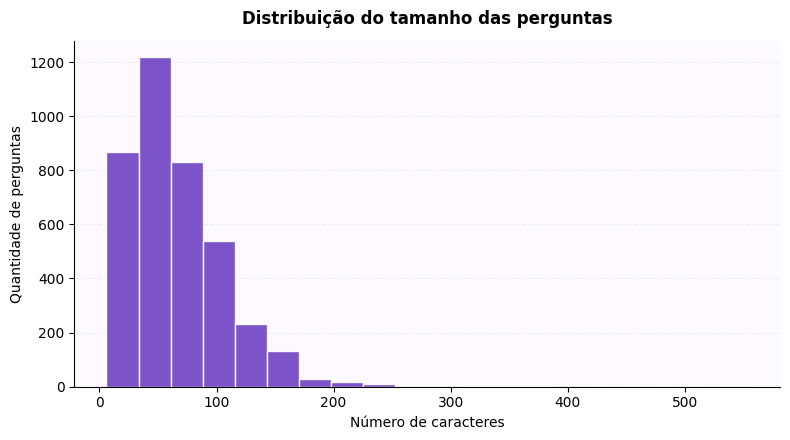

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(
    df["question_chars"],
    bins=20,
    color=ROXO,
    edgecolor="white",
    alpha=0.9
)

ax.set_xlabel("Número de caracteres")
ax.set_ylabel("Quantidade de perguntas")
ax.set_title("Distribuição do tamanho das perguntas", pad=12, weight="bold")

estilizar_grafico(ax)
plt.show()


Há 3.849 perguntas diferentes, com 38 repetições além da primeira ocorrência. O tamanho também varia bastante: a mediana é de 57 caracteres e o maior caso possui 554.


### type_question

A coluna type_question informa o tipo da pergunta, mas possui muitos valores ausentes registrados como texto e também algumas diferenças de escrita entre as categorias.


In [26]:
df["type_question"].head()


0    simple
1    simple
2    simple
3    simple
4    simple
Name: type_question, dtype: object

In [27]:
df["type_question"].value_counts(dropna=False).head(20)


type_question
nan                        2591
simple                      249
                            172
set                         152
comparison                   82
multi-hop                    80
post_processing              80
agregtion                    80
agregation                   75
multi_hop                    73
comparisson                  71
simple com com condição      71
post-processing heavy        54
None                         27
comparrison                  15
simple com condição          15
Name: count, dtype: int64

In [28]:
# transforma marcadores textuais de ausência em valores ausentes
df["type_question_limpa"] = (
    df["type_question"]
    .astype("string")
    .str.strip()
    .replace({
        "": pd.NA,
        "nan": pd.NA,
        "None": pd.NA,
        "none": pd.NA
    })
)

print("Valores ausentes:", df["type_question_limpa"].isna().sum())
print("Valores distintos preenchidos:", df["type_question_limpa"].nunique())


Valores ausentes: 2790
Valores distintos preenchidos: 13


A maior parte dos registros não possui um tipo de pergunta preenchido. Entre os valores presentes também aparecem pequenas diferenças de escrita, então essa coluna precisaria de padronização antes de ser usada diretamente em um modelo.


### type_feature

A coluna type_feature descreve características da pergunta, como formalidade, legibilidade e abstração.


In [29]:
df["type_feature"].head()


0    Lexical entropy low
1    Lexical entropy low
2    Lexical entropy low
3    Lexical entropy low
4    Lexical entropy low
Name: type_feature, dtype: object

In [30]:
df["type_feature"].value_counts(dropna=False).head(20)


type_feature
                                516
indice de legibilidade low      243
indice de legibilidade high     213
comprimento_palavras low        212
nivel_formalidade low           189
ritmo_fluidez low               169
indice_legibilidade low         168
ritmo e fluidez low             162
entropia_lexical low            156
nível de abstração low          156
comprimento de palavras low     141
entropia lexical low            138
nivel_abstracao low             126
entropia lexical high           120
comprimento de palavras high    117
nível de abstração high         114
ritmo e fluidez high            111
entropia_lexical high           111
nivel_formalidade high           96
ritmo_fluidez high               93
Name: count, dtype: int64

In [31]:
# trata apenas os marcadores claros de ausência
df["type_feature_limpa"] = (
    df["type_feature"]
    .astype("string")
    .str.strip()
    .replace({
        "": pd.NA,
        "nan": pd.NA,
        "None": pd.NA,
        "none": pd.NA
    })
)

print("Valores ausentes:", df["type_feature_limpa"].isna().sum())
print("Valores distintos preenchidos:", df["type_feature_limpa"].nunique())


Valores ausentes: 597
Valores distintos preenchidos: 28


Foram encontrados 597 valores ausentes. Também existem variações de idioma e de escrita entre as categorias, por isso a coluna exigiria padronização caso fosse utilizada posteriormente.


### name

A coluna name representa o nome associado à persona do agente.


In [32]:
df["name"].head()


0         Bella
1      Bazarino
2       Felicio
3    Frederico.
4       Maximus
Name: name, dtype: object

In [33]:
print("Nomes distintos:", df["name"].nunique())
df["name"].value_counts().head(10)


Nomes distintos: 834


name
Logan        60
Orlando      57
Lucas        39
Atlas        36
Orion        36
Oliver       33
Aurélio      30
Skyler       30
Andantino    27
Hermes       24
Name: count, dtype: int64

Foram encontrados 834 nomes diferentes. Alguns aparecem várias vezes, o que é esperado para uma característica de persona.


### occupation

A coluna occupation descreve a ocupação associada à persona.


In [34]:
df["occupation"].head()


0                          Atendente de E-commerce
1               Profissão: Atendente de E-commerce
2                          Atendente de E-commerce
3    Atendente de Suporte ao Cliente em E-commerce
4                        Atendente de Loja Virtual
Name: occupation, dtype: object

In [35]:
print("Ocupações distintas:", df["occupation"].nunique())
df["occupation"].value_counts().head(15)


Ocupações distintas: 1724


occupation
E-commerce attendant                 129
Asistente de comercio electrónico    129
Atendente de E-commerce               96
Asistente de atención al cliente      48
Customer support attendant            48
Atendente de Suporte ao Cliente       46
Asistente de servicio al cliente      35
Atendente de e-commerce               33
Customer service attendant            27
Travel agent                          26
Agente de viajes                      26
Asistente de atención al cliente.     24
Customer support attendant.           24
Atendente de Serviço ao Cliente       24
Asistente de la tienda                23
Name: count, dtype: int64

A coluna possui 1.724 valores diferentes. A inspeção mostra que existem ocupações escritas em idiomas diferentes, além de variações de formato e de nível de detalhe. Isso faz com que ocupações parecidas apareçam como valores distintos e ajuda a explicar a grande quantidade de categorias encontradas.


### instructions

A coluna instructions contém uma lista de instruções associadas ao agente.


In [36]:
df["instructions"].head()


0    [Responda sempre educadamente e com empatia, U...
1    [Finalize a resposta com um emoji de animal e ...
2    [Responda de forma objetiva e clara sempre que...
3    [Responda sempre mencionando a Shoes Julis de ...
4    [Em todas as respostas, enfatize a transparênc...
Name: instructions, dtype: object

In [37]:
df["n_instructions"] = df["instructions"].apply(len)

df["n_instructions"].describe()


count    3887.000000
mean        6.190635
std         5.113074
min         1.000000
25%         2.000000
50%         5.000000
75%        10.000000
max        20.000000
Name: n_instructions, dtype: float64

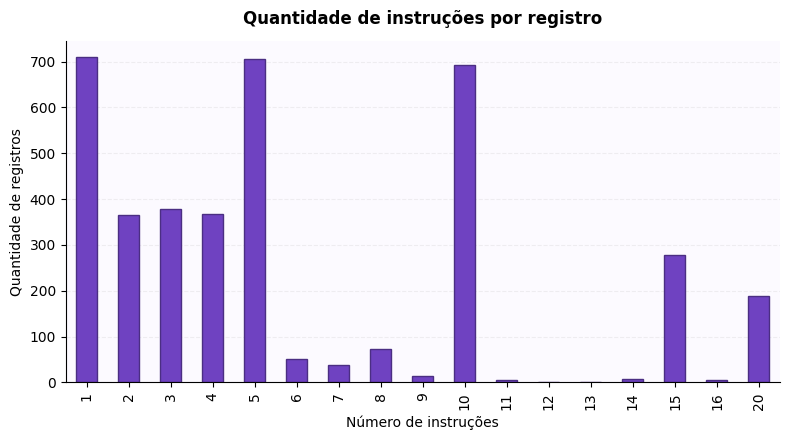

In [38]:
ax = (
    df["n_instructions"]
    .value_counts()
    .sort_index()
    .plot(
        kind="bar",
        figsize=(8, 4.5),
        color=ROXO,
        edgecolor=ROXO_ESCURO
    )
)

ax.set_xlabel("Número de instruções")
ax.set_ylabel("Quantidade de registros")
ax.set_title("Quantidade de instruções por registro", pad=12, weight="bold")

estilizar_grafico(ax)
plt.show()


Cada registro possui entre 1 e 20 instruções. A mediana é 5, então há bastante variação na quantidade de instruções dadas ao agente.


### chatbot_goal

A coluna chatbot_goal descreve o objetivo atribuído ao chatbot.


In [39]:
df["chatbot_goal"].head()


0    Oferecer suporte sobre produtos, frete, person...
1    Facilitar trocas, prazos, contatos, dúvidas, e...
2    O Chatbot é para fornecer informações sobre pa...
3    Proporcionar suporte completo aos clientes Sho...
4    Auxiliar com informações sobre formas de pagam...
Name: chatbot_goal, dtype: object

In [40]:
print("Objetivos distintos:", df["chatbot_goal"].nunique())

df["chatbot_goal_chars"] = df["chatbot_goal"].str.len()
df["chatbot_goal_chars"].describe()


Objetivos distintos: 3881


count    3887.000000
mean      191.895292
std       179.340978
min        16.000000
25%        85.000000
50%       141.000000
75%       244.000000
max      1314.000000
Name: chatbot_goal_chars, dtype: float64

Quase todos os registros possuem um objetivo diferente. O tamanho varia de 16 a 1.314 caracteres, com mediana de 141.


### adjective

A coluna adjective representa um traço da persona.


In [41]:
df["adjective"].head()


0       Criativo
1       Relaxado
2       Generoso
3       Inovador
4    Sistemático
Name: adjective, dtype: object

In [42]:
print("Adjetivos distintos:", df["adjective"].nunique())
df["adjective"].value_counts().head(15)


Adjetivos distintos: 24


adjective
Extrovertido    377
Sistemático     294
Intelectual     273
Organizado      253
Cooperativo     245
Amigável        171
Creative        134
Creativa        133
Systematic      131
Relajada        131
Organized       131
Relaxed         131
Generous        130
Innovative      129
Innovador       129
Name: count, dtype: int64

Foram encontrados 24 valores diferentes. Parte dessa variedade vem do mesmo tipo de característica escrito em idiomas diferentes.


### data_category

A coluna data_category identifica o tipo de tarefa de cada registro.


In [43]:
df["data_category"].head()


0    text_generation
1    text_generation
2    text_generation
3    text_generation
4    text_generation
Name: data_category, dtype: object

In [44]:
contagem_data_category = df["data_category"].value_counts()

pd.DataFrame({
    "Quantidade": contagem_data_category,
    "Percentual": (contagem_data_category / len(df) * 100).round(1)
})


,Quantidade,Percentual
data_category,,
text_generation,1721,44.3
classification,792,20.4
refusal_input,777,20.0
refusal_toxic_behavior,597,15.4


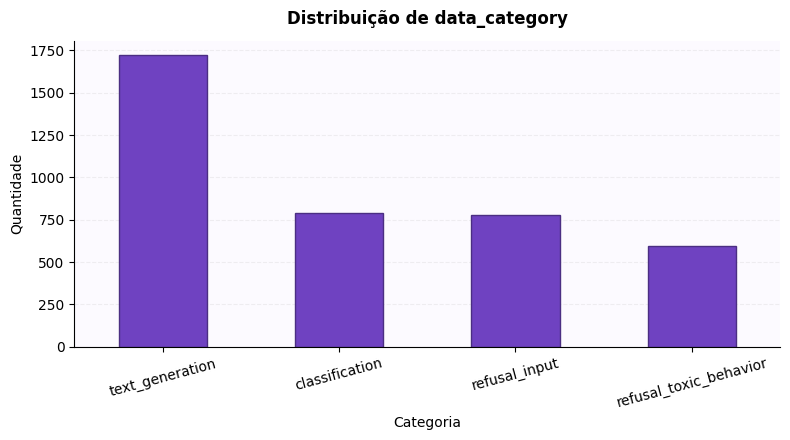

In [45]:
ax = contagem_data_category.plot(
    kind="bar",
    figsize=(8, 4.5),
    color=ROXO,
    edgecolor=ROXO_ESCURO
)

ax.set_xlabel("Categoria")
ax.set_ylabel("Quantidade")
ax.set_title("Distribuição de data_category", pad=12, weight="bold")
ax.tick_params(axis="x", rotation=15)

estilizar_grafico(ax)
plt.show()


A categoria mais frequente é text_generation, com 1.721 registros. As outras três categorias também possuem uma quantidade relevante de exemplos, mas a distribuição não é equilibrada.


### id

A coluna id funciona como identificador, mas não é única por linha.


In [46]:
df["id"].head()


0    1
1    2
2    3
3    4
4    5
Name: id, dtype: object

In [47]:
print("IDs distintos:", df["id"].nunique())
print("Registros com ID já visto:", df["id"].duplicated().sum())

df["id"].value_counts().value_counts().sort_index()


IDs distintos: 1297
Registros com ID já visto: 2590


count
1       1
2       2
3    1294
Name: count, dtype: int64

Existem 1.297 IDs diferentes em 3.887 registros. Quase todos os IDs aparecem três vezes, o que sugere que eles agrupam registros relacionados.


### chunks_big

A coluna chunks_big contém uma lista com conteúdo e score.


In [48]:
from pprint import pprint

pprint(df["chunks_big"].iloc[0][0])


{'content': 'PERGUNTAS FREQUENTES\n'
            '\n'
            '                                                                '
            'Vou receber o mesmo produto da '
            'foto?                                                        \n'
            '\n'
            'Não, pois nossos clientes falam que nossos produtos SÃO AINDA '
            'MAIS LINDOS QUE NAS FOTOS 😍.Brincadeiras a parte, na Bulldog '
            'Bazar nos esforçamos para garantir que as fotos dos produtos em '
            'nosso site sejam o mais precisas possível.\\xa0Portanto, você '
            'deve receber um produto que corresponda à imagem apresentada e '
            'que lhe deixe 100% satisfeito! No entanto, por favor, note que '
            'pode haver pequenas variações devido a diferenças de iluminação e '
            'configurações de tela. Se você tiver alguma preocupação sobre o '
            'produto que recebeu, não hesite em entrar em contato conosco '
            'através do n

In [49]:
df["n_chunks_big"] = df["chunks_big"].apply(len)
df["n_chunks_big"].value_counts().sort_index()


n_chunks_big
1    3887
Name: count, dtype: int64

In [50]:
df["chunk_score"] = df["chunks_big"].apply(
    lambda chunks: chunks[0].get("score") if len(chunks) > 0 else np.nan
)

df["chunk_score"].value_counts(dropna=False).sort_index()


chunk_score
0.0    2165
2.0    1721
NaN       1
Name: count, dtype: int64

Todos os registros possuem exatamente um elemento em chunks_big. O score observado assume principalmente os valores 0 e 2, além de um caso ausente. Como o significado desse score não está claro na documentação consultada, ele não será interpretado além dessa descrição.


### classes

A coluna classes contém uma lista de classes candidatas para cada registro.


In [51]:
print("Exemplo:")
for classe in df["classes"].iloc[0][:3]:
    pprint(classe)


Exemplo:
{'class': 'iluminação',
 'context': 'quando há questões sobre iluminação e como isso pode impactar a '
            'percepção de um produto visto em fotos. Deve-se garantir que as '
            'imagens sejam uma representação precisa do produto real e estar '
            'ciente de possíveis variações devido às diferentes condições de '
            'luz ao visualizar a imagem no site.',
 'id': 'A1'}
{'class': 'personalização em massa',
 'context': 'Personalização em larga escala',
 'id': 'A2'}
{'class': 'fabricação de produtos',
 'context': 'Produção de itens em grande número',
 'id': 'A3'}


In [52]:
df["n_classes"] = df["classes"].apply(len)

df["n_classes"].describe()


count    3887.000000
mean       13.533316
std         6.175746
min         3.000000
25%         9.000000
50%        13.000000
75%        18.000000
max        25.000000
Name: n_classes, dtype: float64

A quantidade de classes varia de 3 a 25 por registro, com mediana de 13. Como cada item também possui contexto e identificador, essa coluna é mais complexa do que uma categoria simples.


### chosen_class_id

A coluna chosen_class_id informa o identificador escolhido em cada registro.


In [53]:
df["chosen_class_id"].head()


0    P1
1    P1
2    P1
3    P1
4    P1
Name: chosen_class_id, dtype: object

In [54]:
df["chosen_class_id"].value_counts()


chosen_class_id
P1     1721
N1      777
S1      597
A1      135
A2      132
A3       93
A5       90
A4       81
A6       57
A8       45
A7       42
A11      21
A12      21
A10      21
A9       18
A13      18
A14       9
A16       6
A15       3
Name: count, dtype: int64

In [55]:
pd.crosstab(
    df["data_category"],
    df["chosen_class_id"]
)


chosen_class_id,A1,A10,A11,A12,A13,A14,A15,A16,A2,A3,A4,A5,A6,A7,A8,A9,N1,P1,S1
data_category,,,,,,,,,,,,,,,,,,,
classification,135,21,21,21,18,9,3,6,132,93,81,90,57,42,45,18,0,0,0
refusal_input,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,777,0,0
refusal_toxic_behavior,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,597
text_generation,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1721,0


In [56]:
# verifica se a classe escolhida aparece entre as opções nos registros de classificação
df_classificacao = df[df["data_category"] == "classification"].copy()

def classe_escolhida_existe(row):
    ids_disponiveis = [classe.get("id") for classe in row["classes"]]
    return row["chosen_class_id"] in ids_disponiveis

df_classificacao["classe_valida"] = df_classificacao.apply(
    classe_escolhida_existe,
    axis=1
)

df_classificacao["classe_valida"].value_counts()


classe_valida
True    792
Name: count, dtype: int64

Nos 792 registros de classification, a classe escolhida aparece entre as classes candidatas em todos os casos. Nas outras categorias, chosen_class_id segue outros padrões, como P1, N1 e S1.


### language

A coluna language indica o idioma do registro: 0 para português, 1 para inglês e 2 para espanhol.


In [57]:
df["language"].head()


0    0
1    0
2    0
3    0
4    0
Name: language, dtype: int64

In [58]:
mapa_idiomas = {
    0: "pt-br",
    1: "en-us",
    2: "es-es"
}

df["language_label"] = df["language"].map(mapa_idiomas)

contagem_idiomas = df["language_label"].value_counts()
contagem_idiomas


language_label
pt-br    1296
en-us    1296
es-es    1295
Name: count, dtype: int64

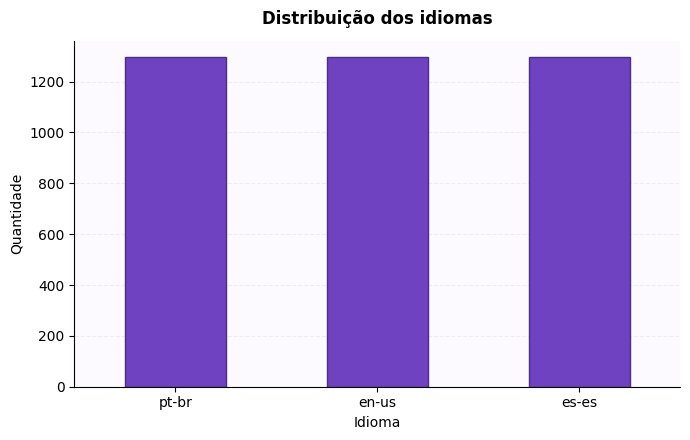

In [59]:
ax = contagem_idiomas.plot(
    kind="bar",
    figsize=(7, 4.5),
    color=ROXO,
    edgecolor=ROXO_ESCURO
)

ax.set_xlabel("Idioma")
ax.set_ylabel("Quantidade")
ax.set_title("Distribuição dos idiomas", pad=12, weight="bold")
ax.tick_params(axis="x", rotation=0)

estilizar_grafico(ax)
plt.show()


Os três idiomas estão praticamente equilibrados, com cerca de 1.296 registros em cada um.


### data_category_QA

A coluna data_category_QA possui três categorias: positivo, negativo e sensíveis.


In [60]:
df["data_category_QA"].head()


0    positivo
1    positivo
2    positivo
3    positivo
4    positivo
Name: data_category_QA, dtype: object

In [61]:
df["data_category_QA"].value_counts()


data_category_QA
positivo     1721
negativo     1569
sensíveis     597
Name: count, dtype: int64

In [62]:
pd.crosstab(
    df["data_category"],
    df["data_category_QA"]
)


data_category_QA,negativo,positivo,sensíveis
data_category,,,
classification,792,0,0
refusal_input,777,0,0
refusal_toxic_behavior,0,0,597
text_generation,0,1721,0


A tabela mostra uma relação direta entre data_category e data_category_QA. Por exemplo, todos os registros de text_generation são positivos e todos os de refusal_toxic_behavior são sensíveis.


### content_base_uuids

A coluna content_base_uuids contém identificadores associados aos conteúdos-base.


In [63]:
df["content_base_uuids"].head()


0    5db3c3c5-c9fc-44ec-991d-dc32f9bd37d5
1    e7d321f2-e0f7-4ee7-aa0d-cb7947b837bf
2    363de0bd-a2fe-4045-92d3-6af39fc97f17
3    1eb07a54-7803-4816-b146-2c8a5e82e497
4    61f16329-e698-4106-88c7-fd23dac0a70d
Name: content_base_uuids, dtype: object

In [64]:
print("UUIDs distintos:", df["content_base_uuids"].nunique())
print("UUIDs duplicados:", df["content_base_uuids"].duplicated().sum())


UUIDs distintos: 3887
UUIDs duplicados: 0


Todos os 3.887 valores são únicos. Como o próprio content se repete, esse identificador não deve ser usado sozinho para detectar conteúdos repetidos.


## Algumas relações importantes

Depois da análise individual das colunas, algumas relações ajudam a entender melhor a estrutura do conjunto.


### Valores ausentes por idioma e tarefa


In [65]:
ausencia_type_question_idioma = (
    df.assign(ausente=df["type_question_limpa"].isna())
    .groupby("language_label")["ausente"]
    .mean()
    .mul(100)
    .round(1)
)

ausencia_type_feature_tarefa = (
    df.assign(ausente=df["type_feature_limpa"].isna())
    .groupby("data_category")["ausente"]
    .mean()
    .mul(100)
    .round(1)
)

print("Ausência de type_question por idioma (%)")
display(ausencia_type_question_idioma)

print("Ausência de type_feature por tarefa (%)")
display(ausencia_type_feature_tarefa)


Ausência de type_question por idioma (%)


language_label
en-us    100.0
es-es    100.0
pt-br     15.4
Name: ausente, dtype: float64

Ausência de type_feature por tarefa (%)


data_category
classification              0.0
refusal_input               0.0
refusal_toxic_behavior    100.0
text_generation             0.0
Name: ausente, dtype: float64

A ausência não está distribuída da mesma forma em toda a base. type_question está ausente em todos os registros em inglês e espanhol, enquanto type_feature está ausente em todos os registros de refusal_toxic_behavior. Por isso, esses campos não devem ser tratados como se os valores estivessem faltando ao acaso.


### Repetição entre idiomas


In [66]:
idiomas_por_id = (
    df.groupby("id")["language_label"]
    .nunique()
    .value_counts()
    .sort_index()
)

idiomas_por_id


language_label
1       1
2       2
3    1294
Name: count, dtype: int64

Dos 1.297 IDs, 1.294 aparecem nos três idiomas. Isso reforça que muitos registros são versões relacionadas e não exemplos totalmente independentes.


### Reutilização de conteúdo


In [67]:
# normalização simples para encontrar conteúdos textualmente equivalentes
df["content_normalizado"] = (
    df["content"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

frequencia_conteudo_normalizado = df["content_normalizado"].value_counts()

print("Conteúdos únicos antes:", df["content"].nunique())
print("Conteúdos únicos após normalização:", df["content_normalizado"].nunique())
print(
    "Conteúdos usados por mais de uma amostra:",
    (frequencia_conteudo_normalizado > 1).sum()
)
print(
    "Maior número de ocorrências:",
    frequencia_conteudo_normalizado.max()
)


Conteúdos únicos antes: 548
Conteúdos únicos após normalização: 535
Conteúdos usados por mais de uma amostra: 535
Maior número de ocorrências: 51


Depois de uma normalização simples de espaços e letras maiúsculas ou minúsculas, os 548 conteúdos passam para 535 textos diferentes. Todos esses conteúdos aparecem mais de uma vez. Isso precisa ser considerado caso seja criada uma divisão de treino e teste.


### Sobreposição em uma divisão aleatória


In [68]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

train = df.iloc[train_idx]
test = df.iloc[test_idx]

ids_em_comum = set(train["id"]) & set(test["id"])
conteudos_em_comum = (
    set(train["content_normalizado"])
    & set(test["content_normalizado"])
)

print("IDs presentes nos dois conjuntos:", len(ids_em_comum))
print("Conteúdos presentes nos dois conjuntos:", len(conteudos_em_comum))


IDs presentes nos dois conjuntos: 616
Conteúdos presentes nos dois conjuntos: 357


Na divisão aleatória usada apenas como teste, 616 IDs e 357 conteúdos aparecem tanto no treino quanto no teste. Isso mostra que uma divisão aleatória simples pode colocar exemplos relacionados nos dois conjuntos. Se houver treinamento, seria melhor separar os dados levando esses grupos em consideração.


## Possíveis outliers

Para observar valores muito distantes do restante da distribuição, foi usado o intervalo interquartil nos comprimentos de content, question e chatbot_goal. Esses casos não são necessariamente erros, principalmente porque textos podem ter tamanhos muito diferentes.


In [69]:
colunas_para_outliers = [
    "content_chars",
    "question_chars",
    "chatbot_goal_chars"
]

resumo_outliers = []

for coluna in colunas_para_outliers:
    serie = df[coluna].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    quantidade = (
        (serie < limite_inferior) |
        (serie > limite_superior)
    ).sum()

    resumo_outliers.append({
        "variavel": coluna,
        "possiveis_outliers": int(quantidade)
    })

pd.DataFrame(resumo_outliers)


,variavel,possiveis_outliers
0,content_chars,18
1,question_chars,75
2,chatbot_goal_chars,230


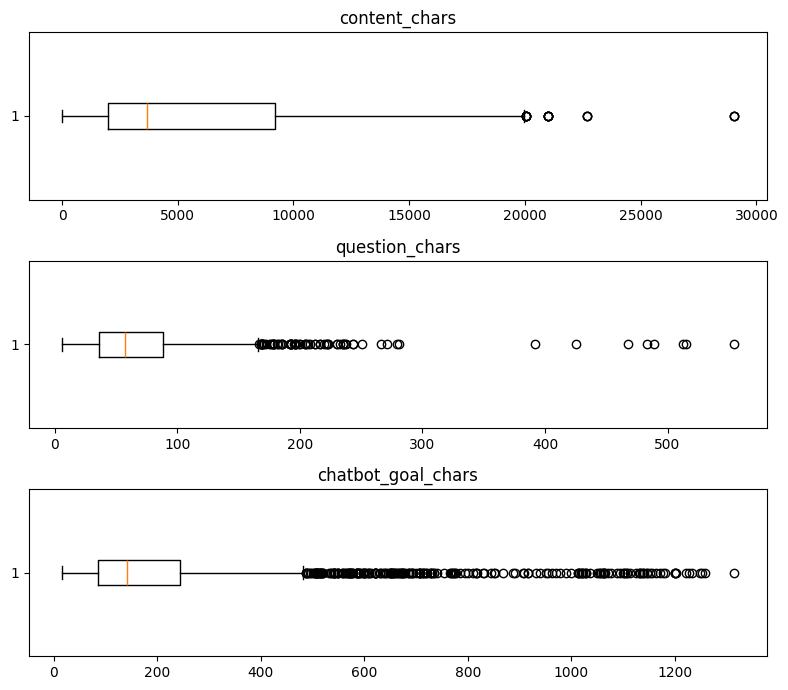

In [70]:
fig, axes = plt.subplots(3, 1, figsize=(8, 7))

for ax, coluna in zip(axes, colunas_para_outliers):
    ax.boxplot(
        df[coluna].dropna(),
        vert=False
    )
    ax.set_title(coluna)

plt.tight_layout()
plt.show()


Pelo critério do IQR, foram encontrados 18 casos extremos no tamanho de content, 75 no tamanho de question e 230 no tamanho de chatbot_goal. Eles não serão removidos automaticamente, porque um texto longo pode ser válido.


## Pontos importantes para as próximas etapas

A EDA mostrou alguns cuidados que podem influenciar o pré-processamento e a avaliação.

- Valores como nan, None e strings vazias precisam ser tratados como ausentes em algumas colunas.
- Há bastante repetição de conteúdo e de IDs entre idiomas, então uma divisão aleatória pode misturar exemplos relacionados entre treino e teste.
- Algumas categorias possuem formas diferentes de escrita ou idioma e precisariam ser padronizadas se fossem utilizadas.
- Os textos têm tamanhos muito diferentes, o que deve ser considerado ao escolher limites de entrada e estratégias de divisão do texto.
- data_category e data_category_QA carregam informações muito parecidas, então não faria sentido tratá-las como variáveis independentes sem verificar o objetivo do modelo.


## Limitações desta EDA

A análise de conteúdos repetidos foi feita com uma normalização textual simples. Textos parecidos, mas escritos de formas diferentes, ainda podem não ser identificados como relacionados.

Também foram usados caracteres para comparar o tamanho dos textos. Caso um modelo específico seja escolhido, a contagem em tokens pode ser mais adequada para decidir limites de entrada.


## Principais conclusões da EDA

O conjunto possui 3.887 registros, quatro tipos de tarefa e três idiomas praticamente equilibrados.

Os principais pontos encontrados foram a grande reutilização de conteúdos, a repetição de IDs entre os idiomas, a presença de valores ausentes registrados como texto e algumas categorias com diferenças de escrita. Também há bastante variação no tamanho dos textos.

Esses resultados indicam que o pré-processamento deve tratar ausências e inconsistências com cuidado e que uma eventual divisão de treino e teste não deve ser feita de forma totalmente aleatória, para evitar que exemplos muito relacionados apareçam nos dois conjuntos.
